OASIS INFOBYTE - DATA ANALYTICS INTERNSHIP

Task: EDA on Retail Sales Data

Intern: Eseonu Rejoice Adaeze

Dataset: Customer Shopping Dataset - Retail Sales Data

Source: Kaggle, Mehmet Tahir Aslan

In [1]:
# importing the libraries
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
# loading the dataset
df_raw = pd.read_csv('customer_shopping_data.csv')

In [3]:
# making a copy of the raw dataset
df = df_raw.copy()
df.head(10)

,invoice_no,customer_id,gender,age,category,quantity,price,payment_method,invoice_date,shopping_mall
0,I138884,C241288,Female,28,Clothing,5,1500.40,Credit Card,5/8/2022,Kanyon
1,I317333,C111565,Male,21,Shoes,3,1800.51,Debit Card,12/12/2021,Forum Istanbul
2,I127801,C266599,Male,20,Clothing,1,300.08,Cash,9/11/2021,Metrocity
3,I173702,C988172,Female,66,Shoes,5,3000.85,Credit Card,16/05/2021,Metropol AVM
4,I337046,C189076,Female,53,Books,4,60.60,Cash,24/10/2021,Kanyon
5,I227836,C657758,Female,28,Clothing,5,1500.40,Credit Card,24/05/2022,Forum Istanbul
6,I121056,C151197,Female,49,Cosmetics,1,40.66,Cash,13/03/2022,Istinye Park
7,I293112,C176086,Female,32,Clothing,2,600.16,Credit Card,13/01/2021,Mall of Istanbul
8,I293455,C159642,Male,69,Clothing,3,900.24,Credit Card,4/11/2021,Metrocity
9,I326945,C283361,Female,60,Clothing,2,600.16,Credit Card,22/08/2021,Kanyon


In [4]:
# last 5 rows
df.tail()

,invoice_no,customer_id,gender,age,category,quantity,price,payment_method,invoice_date,shopping_mall
99452,I219422,C441542,Female,45,Souvenir,5,58.65,Credit Card,21/09/2022,Kanyon
99453,I325143,C569580,Male,27,Food & Beverage,2,10.46,Cash,22/09/2021,Forum Istanbul
99454,I824010,C103292,Male,63,Food & Beverage,2,10.46,Debit Card,28/03/2021,Metrocity
99455,I702964,C800631,Male,56,Technology,4,4200.00,Cash,16/03/2021,Istinye Park
99456,I232867,C273973,Female,36,Souvenir,3,35.19,Credit Card,15/10/2022,Mall of Istanbul


In [5]:
# dataset dimensions
df.shape

(99457, 10)

In [6]:
# summary of the dataset
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 99457 entries, 0 to 99456
Data columns (total 10 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   invoice_no      99457 non-null  str    
 1   customer_id     99457 non-null  str    
 2   gender          99457 non-null  str    
 3   age             99457 non-null  int64  
 4   category        99457 non-null  str    
 5   quantity        99457 non-null  int64  
 6   price           99457 non-null  float64
 7   payment_method  99457 non-null  str    
 8   invoice_date    99457 non-null  str    
 9   shopping_mall   99457 non-null  str    
dtypes: float64(1), int64(2), str(7)
memory usage: 12.9 MB


In [7]:
# descriptive statistics of numerical columns
df.describe()

,age,quantity,price
count,99457.000000,99457.000000,99457.000000
mean,43.427089,3.003429,689.256321
std,14.990054,1.413025,941.184567
min,18.000000,1.000000,5.230000
25%,30.000000,2.000000,45.450000
50%,43.000000,3.000000,203.300000
75%,56.000000,4.000000,1200.320000
max,69.000000,5.000000,5250.000000


In [8]:
df.columns

Index(['invoice_no', 'customer_id', 'gender', 'age', 'category', 'quantity',
       'price', 'payment_method', 'invoice_date', 'shopping_mall'],
      dtype='str')

In [9]:
# checking unique values in the text columns
text_cols = ['gender', 'category', 'payment_method', 'shopping_mall']
for col in text_cols:
    print(f'{col}:', df[col].unique())

gender: <ArrowStringArray>
['Female', 'Male']
Length: 2, dtype: str
category: <ArrowStringArray>
[       'Clothing',           'Shoes',           'Books',       'Cosmetics',
 'Food & Beverage',            'Toys',      'Technology',        'Souvenir']
Length: 8, dtype: str
payment_method: <ArrowStringArray>
['Credit Card', 'Debit Card', 'Cash']
Length: 3, dtype: str
shopping_mall: <ArrowStringArray>
[           'Kanyon',    'Forum Istanbul',         'Metrocity',
      'Metropol AVM',      'Istinye Park',  'Mall of Istanbul',
 'Emaar Square Mall',       'Cevahir AVM',    'Viaport Outlet',
      'Zorlu Center']
Length: 10, dtype: str


In [10]:
# checking for nulls
df.isna().sum()

invoice_no        0
customer_id       0
gender            0
age               0
category          0
quantity          0
price             0
payment_method    0
invoice_date      0
shopping_mall     0
dtype: int64

In [11]:
# checking for duplicates
df.duplicated().sum()

np.int64(0)

In [12]:
# checking the unique values in the invoice date column
df['invoice_date'].unique()

<ArrowStringArray>
[  '5/8/2022', '12/12/2021',  '9/11/2021', '16/05/2021', '24/10/2021',
 '24/05/2022', '13/03/2022', '13/01/2021',  '4/11/2021', '22/08/2021',
 ...
  '12/6/2022',   '1/2/2021',   '2/7/2021',   '7/3/2021', '18/05/2021',
 '29/01/2021',   '1/1/2021',  '12/8/2021',   '8/1/2022',  '11/5/2021']
Length: 797, dtype: str

In [13]:
# converting invoice data from str type to datetime
df['invoice_date'] = pd.to_datetime(df['invoice_date'], dayfirst = True)

In [14]:
df['invoice_date'].dtypes

dtype('<M8[us]')

In [15]:
# checking price and quantity for each category
category_df = df[df['category'] == 'Clothing']
print(category_df[['category', 'price', 'quantity']])

       category    price  quantity
0      Clothing  1500.40         5
2      Clothing   300.08         1
5      Clothing  1500.40         5
7      Clothing   600.16         2
8      Clothing   900.24         3
...         ...      ...       ...
99435  Clothing   900.24         3
99436  Clothing  1500.40         5
99440  Clothing   300.08         1
99442  Clothing  1200.32         4
99449  Clothing   300.08         1

[34487 rows x 3 columns]


In [16]:
category_df = df[df['category'] == 'Food & Beverage']
print(category_df[['category', 'price', 'quantity']])

              category  price  quantity
10     Food & Beverage  10.46         2
17     Food & Beverage  15.69         3
21     Food & Beverage   5.23         1
35     Food & Beverage   5.23         1
40     Food & Beverage  15.69         3
...                ...    ...       ...
99441  Food & Beverage  20.92         4
99445  Food & Beverage  26.15         5
99446  Food & Beverage   5.23         1
99453  Food & Beverage  10.46         2
99454  Food & Beverage  10.46         2

[14776 rows x 3 columns]


The price column represents the total sales value (unit_price * quantity). It is not unit_price for each category.

In [17]:
# renaming price to revenue since it represents total and not unit price
df = df.rename(columns= {'price': 'revenue'})

In [18]:
# calculating a unit_price column from revenue and quantity
df['unit_price'] = df['revenue'] /df['quantity']
df.head()

,invoice_no,customer_id,gender,age,category,quantity,revenue,payment_method,invoice_date,shopping_mall,unit_price
0,I138884,C241288,Female,28,Clothing,5,1500.40,Credit Card,2022-08-05,Kanyon,300.08
1,I317333,C111565,Male,21,Shoes,3,1800.51,Debit Card,2021-12-12,Forum Istanbul,600.17
2,I127801,C266599,Male,20,Clothing,1,300.08,Cash,2021-11-09,Metrocity,300.08
3,I173702,C988172,Female,66,Shoes,5,3000.85,Credit Card,2021-05-16,Metropol AVM,600.17
4,I337046,C189076,Female,53,Books,4,60.60,Cash,2021-10-24,Kanyon,15.15


In [19]:
# checking unit_price per category
df.groupby('category')['unit_price'].nunique()

category
Books              1
Clothing           2
Cosmetics          2
Food & Beverage    2
Shoes              1
Souvenir           2
Technology         1
Toys               2
Name: unit_price, dtype: int64

In [20]:
df.groupby('category')['unit_price'].unique()

category
Books                                   [15.15]
Clothing           [300.08000000000004, 300.08]
Cosmetics           [40.66, 40.660000000000004]
Food & Beverage      [5.23, 5.2299999999999995]
Shoes                                  [600.17]
Souvenir            [11.73, 11.729999999999999]
Technology                             [1050.0]
Toys                [35.84, 35.839999999999996]
Name: unit_price, dtype: object

In [21]:
# rounding unit_price column to 2 d.p
df['unit_price'] = df['unit_price'].round(2)

In [22]:
df.groupby('category')['unit_price'].nunique()

category
Books              1
Clothing           1
Cosmetics          1
Food & Beverage    1
Shoes              1
Souvenir           1
Technology         1
Toys               1
Name: unit_price, dtype: int64

In [23]:
# adding new columns to the dataset
df['year'] = df['invoice_date'].dt.year
df['month'] = df['invoice_date'].dt.month
df['quarter'] = df['invoice_date'].dt.quarter
df.head()

,invoice_no,customer_id,gender,age,category,quantity,revenue,payment_method,invoice_date,shopping_mall,unit_price,year,month,quarter
0,I138884,C241288,Female,28,Clothing,5,1500.40,Credit Card,2022-08-05,Kanyon,300.08,2022,8,3
1,I317333,C111565,Male,21,Shoes,3,1800.51,Debit Card,2021-12-12,Forum Istanbul,600.17,2021,12,4
2,I127801,C266599,Male,20,Clothing,1,300.08,Cash,2021-11-09,Metrocity,300.08,2021,11,4
3,I173702,C988172,Female,66,Shoes,5,3000.85,Credit Card,2021-05-16,Metropol AVM,600.17,2021,5,2
4,I337046,C189076,Female,53,Books,4,60.60,Cash,2021-10-24,Kanyon,15.15,2021,10,4


In [24]:
# creating age_group column
bins = [17, 25, 35, 45, 55, 70]
labels = ['18-25', '26-35', '36-45', '46-55', '56+']
df['age_group'] = pd.cut(
    df['age'], 
    bins = bins,
    labels = labels
)

DESCRIPTIVE STATISTICS

In [25]:
# identifying the numerical columns
df.select_dtypes(include= 'number').columns

Index(['age', 'quantity', 'revenue', 'unit_price', 'year', 'month', 'quarter'], dtype='str')

In [26]:
# selecting the specific numeric columns
num_cols = df.select_dtypes(include= 'number').columns
exclude_cols = ['year', 'month', 'quarter']

numeric_cols = num_cols.drop(exclude_cols)
numeric_cols

Index(['age', 'quantity', 'revenue', 'unit_price'], dtype='str')

In [27]:
# calculating the mean, median, and standard deviation
stats = df[numeric_cols].agg(['mean', 'median', 'std', 'min', 'max'])
stats

,age,quantity,revenue,unit_price
mean,43.427089,3.003429,689.256321,229.280048
median,43.000000,3.000000,203.300000,40.660000
std,14.990054,1.413025,941.184567,266.047550
min,18.000000,1.000000,5.230000,5.230000
max,69.000000,5.000000,5250.000000,1050.000000


In [28]:
modes = df[numeric_cols].mode()
modes

,age,quantity,revenue,unit_price
0,37,3,600.16,300.08


In [29]:
# to check values across categories
category_summary = (
    df.groupby('category')
    .agg(
        transactions = ('invoice_no', 'count'),
        total_revenue = ('revenue', 'sum'),
        avg_revenue = ('revenue', 'mean'),
        median_revenue = ('revenue', 'median'),
        max_revenue = ('revenue', 'max'),
        total_qty = ('quantity', 'sum'),
        avg_qty = ('quantity', 'mean'),
        unit_price = ('unit_price', 'first'),
    )
    .sort_values(by = 'total_revenue', ascending = False)
)
category_summary

,transactions,total_revenue,avg_revenue,median_revenue,max_revenue,total_qty,avg_qty,unit_price
category,,,,,,,,
Clothing,34487,31075684.64,901.084021,900.24,1500.40,103558,3.002813,300.08
Shoes,10034,18135336.89,1807.388568,1800.51,3000.85,30217,3.011461,600.17
Technology,4996,15772050.00,3156.935548,3150.00,5250.00,15021,3.006605,1050.00
Cosmetics,15097,1848606.90,122.448626,121.98,203.30,45465,3.011525,40.66
Toys,10087,1086704.64,107.733185,107.52,179.20,30321,3.005948,35.84
Food & Beverage,14776,231568.71,15.671948,15.69,26.15,44277,2.996548,5.23
Books,4981,226977.30,45.568621,45.45,75.75,14982,3.007830,15.15
Souvenir,4999,174436.83,34.894345,35.19,58.65,14871,2.974795,11.73


The descriptive statistics provided an overview of customer age, quantities purchased, product prices and revenue.

Customer age: Customers are between 18 and 69 years old, with typical age of 43. The mean and median are identical (43 years), showing an even spread across the age groups, with 37 as the most common age.

Quantity: Customers buy between 1 and 5 items per transaction. The average, median and most common quantity are all 3 items, meaning that the quantities are steady and consistent across the dataset.

Revenue and Unit Price: Both revenue and unit price are pulled upward by a few expensive items. They show a right-skewed distribution as the mean is about 3x more above the median.

Since customers buy between 1 and 5 items, higher revenue comes from the product price rather than large bulk orders. High-priced categories like Technology (1,050.00), Shoes (600.17) and Clothing (300.08) push the mean up, while everyday categories like Food and Beverage and Books keep the average order value lower.  

In [30]:
df[numeric_cols].describe()

,age,quantity,revenue,unit_price
count,99457.000000,99457.000000,99457.000000,99457.000000
mean,43.427089,3.003429,689.256321,229.280048
std,14.990054,1.413025,941.184567,266.047550
min,18.000000,1.000000,5.230000,5.230000
25%,30.000000,2.000000,45.450000,35.840000
50%,43.000000,3.000000,203.300000,40.660000
75%,56.000000,4.000000,1200.320000,300.080000
max,69.000000,5.000000,5250.000000,1050.000000


TIME SERIES ANALYSIS

In [31]:
# checking the date column again
df['invoice_date'].dtype

dtype('<M8[us]')

In [32]:
# seting the invoice date as index
monthly_sales = (
    df.set_index('invoice_date')['revenue']
    .resample('ME')
        .sum()
)
monthly_sales

invoice_date
2021-01-31    2656422.78
2021-02-28    2358636.34
2021-03-31    2618434.14
2021-04-30    2558825.62
2021-05-31    2662369.93
2021-06-30    2547239.73
2021-07-31    2802468.58
2021-08-31    2632303.32
2021-09-30    2530305.88
2021-10-31    2782418.40
2021-11-30    2547152.35
2021-12-31    2619727.56
2022-01-31    2656149.96
2022-02-28    2318201.08
2022-03-31    2705190.76
2022-04-30    2543653.14
2022-05-31    2684556.89
2022-06-30    2613106.01
2022-07-31    2749554.99
2022-08-31    2638238.71
2022-09-30    2584908.39
2022-10-31    2755839.69
2022-11-30    2447988.76
2022-12-31    2675437.80
2023-01-31    2620053.89
2023-02-28    2558459.90
2023-03-31     683721.31
Freq: ME, Name: revenue, dtype: float64

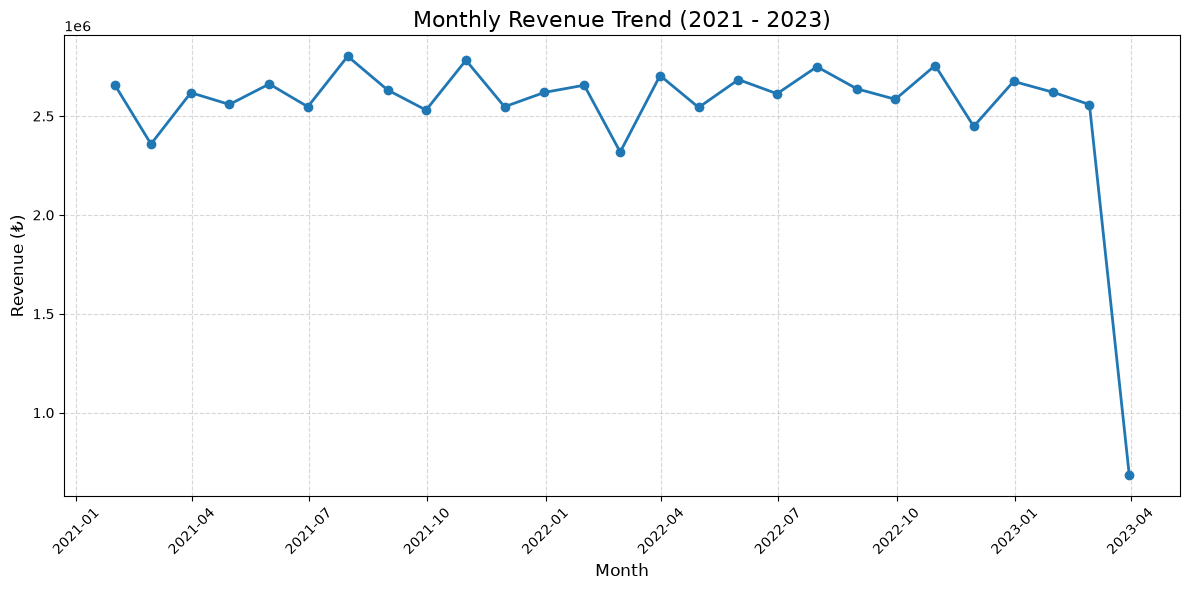

In [33]:
# visualizing monthly revenue
plt.figure(figsize= (12, 6))

plt.plot(
    monthly_sales.index,
    monthly_sales.values, 
    marker = 'o',
    linestyle = '-',
    linewidth = 2
)

plt.title('Monthly Revenue Trend (2021 - 2023)', fontsize = 16)
plt.xlabel('Month', fontsize = 12)
plt.ylabel('Revenue (₺)', fontsize = 12)

plt.xticks(rotation = 45)
plt.grid(True, linestyle = '--', alpha = 0.5)
plt.tight_layout()
plt.show()

In [34]:
# formatting the revenue
from matplotlib.ticker import FuncFormatter

# Creating the formatter
def format_lira(value, position):
    if value >= 1_000_000:
        return f'₺{value/1_000_000:.1f}M'
    elif value >= 1_000:
        return f'₺{value/1_000:.0f}K'
    else:
        return f'₺{value:,.0f}'

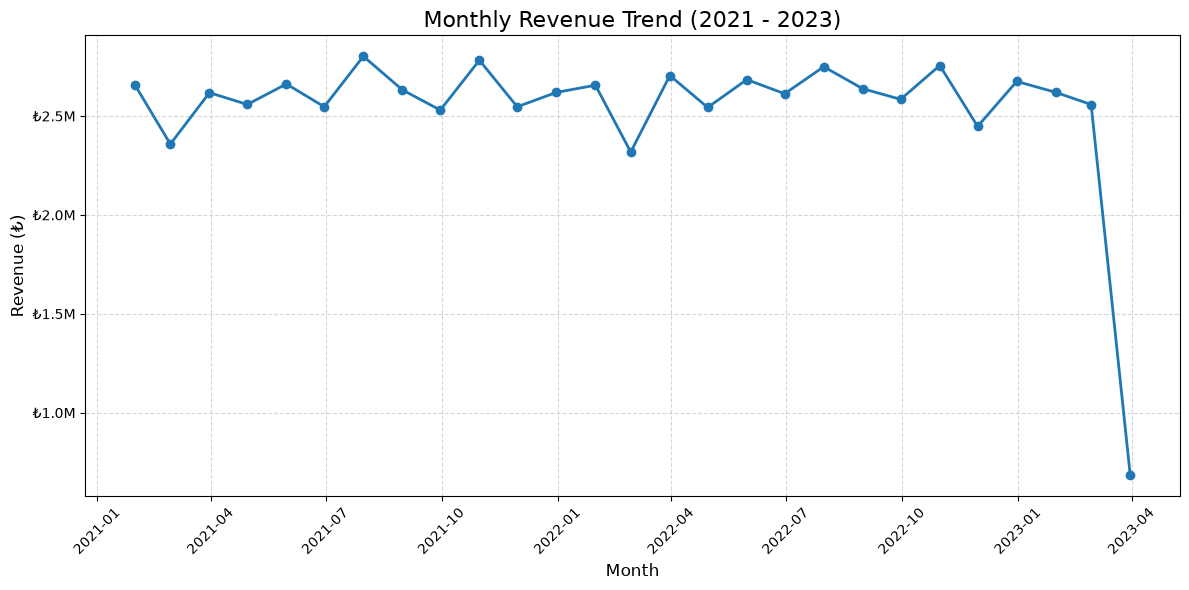

In [35]:
plt.figure(figsize= (12, 6))

plt.plot(
    monthly_sales.index,
    monthly_sales.values, 
    marker = 'o',
    linestyle = '-',
    linewidth = 2
)

plt.title('Monthly Revenue Trend (2021 - 2023)', fontsize = 16)
plt.xlabel('Month', fontsize = 12)
plt.ylabel('Revenue (₺)', fontsize = 12)

plt.gca().yaxis.set_major_formatter(FuncFormatter (format_lira))

plt.xticks(rotation = 45)
plt.grid(True, linestyle = '--', alpha = 0.5)
plt.tight_layout()
plt.show()

In [36]:
# checking why the last month is showing as a sales drop
df['invoice_date'].max()

Timestamp('2023-03-08 00:00:00')

In [37]:
# resampling into quarters
quarterly_sales = (
    df.set_index('invoice_date')['revenue']
    .resample('QE')
        .sum()
)
quarterly_sales

invoice_date
2021-03-31    7633493.26
2021-06-30    7768435.28
2021-09-30    7965077.78
2021-12-31    7949298.31
2022-03-31    7679541.80
2022-06-30    7841316.04
2022-09-30    7972702.09
2022-12-31    7879266.25
2023-03-31    5862235.10
Freq: QE-DEC, Name: revenue, dtype: float64

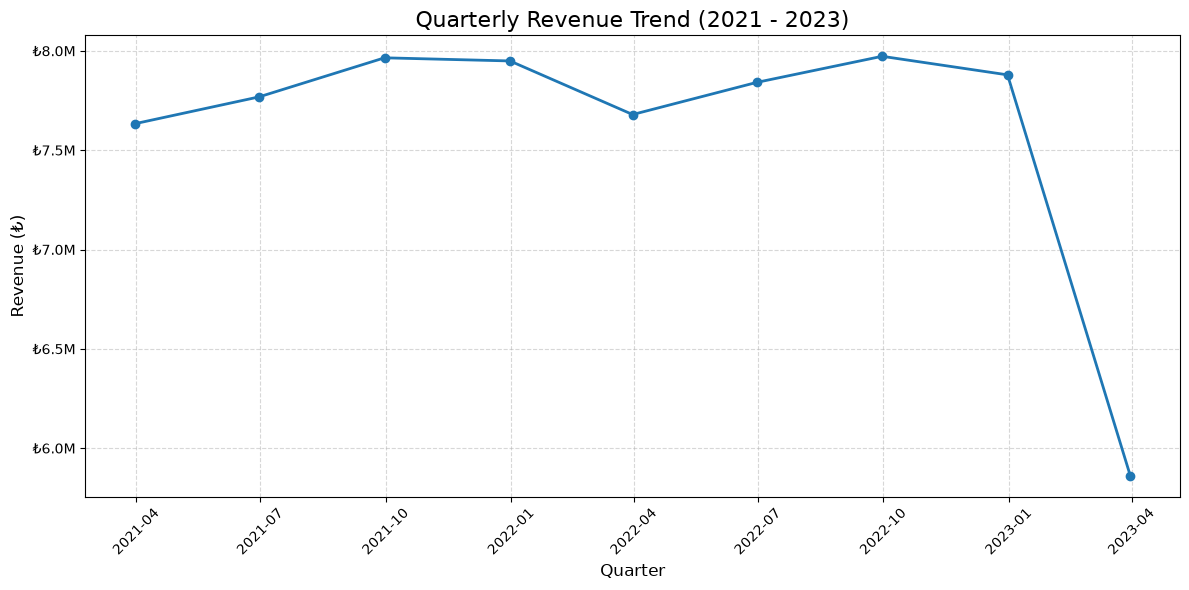

In [38]:
# visualizing quarterly trends
plt.figure(figsize= (12, 6))

plt.plot(
    quarterly_sales.index,
    quarterly_sales.values, 
    marker = 'o',
    linestyle = '-',
    linewidth = 2,
    markersize = 6
)

plt.title('Quarterly Revenue Trend (2021 - 2023)', fontsize = 16)
plt.xlabel('Quarter', fontsize = 12)
plt.ylabel('Revenue (₺)', fontsize = 12)

plt.gca().yaxis.set_major_formatter(FuncFormatter (format_lira))

plt.xticks(rotation = 45)
plt.grid(True, linestyle = '--', alpha = 0.5)
plt.tight_layout()
plt.show()

Highest & Lowest periods: July 2021 (₺2.8M) and Q3 2021 (₺7.95M) recorded the highest sales, while February 2022 (₺2.31M) and Q1 2021 (₺7.63M) had the lowest sales among complete periods.

The sharp drop in March 2023 and Q1 2023 is due to the dataset ending on 2023-03-08, and does not represent a true sales drop.

Sales stay steady with no extreme spikes. Small dips are seen every February simply because February has fewer days (28 days compared to the 30-31 days seen in other months). Across each year, sales climb from Q1 to Q3(the peak quarter), then dip slightly in Q4 instead of jumping at year-end.

2021 and 2022 performed almost identically (₺31.3M each), with the same months and quarters following a similar pattern each year.  

CUSTOMER DEMOGRAPHICS ANALYSIS

In [39]:
# identifying the customers
customers = df.drop_duplicates(subset = 'customer_id')
print(len(customers))

99457


In [40]:
# which age group spends more per transaction
df.groupby('age_group', observed = True)['revenue'].mean().round(2)

age_group
18-25    680.04
26-35    687.41
36-45    699.92
46-55    691.90
56+      686.22
Name: revenue, dtype: float64

In [41]:
# how many customers per age group
print('no of customers:\n', df['age_group'].value_counts().sort_index())
print('\npct of customers:', (df['age_group'].value_counts(normalize = True).sort_index() * 100).round(2),
     )

no of customers:
 age_group
18-25    15359
26-35    19059
36-45    19436
46-55    19016
56+      26587
Name: count, dtype: int64

pct of customers: age_group
18-25    15.44
26-35    19.16
36-45    19.54
46-55    19.12
56+      26.73
Name: proportion, dtype: float64


In [42]:
print('gender distribution:\n', df['gender'].value_counts())
print('\npct of customers:', (df['gender'].value_counts(normalize = True).sort_index() * 100).round(2))

gender distribution:
 gender
Female    59482
Male      39975
Name: count, dtype: int64

pct of customers: gender
Female    59.81
Male      40.19
Name: proportion, dtype: float64


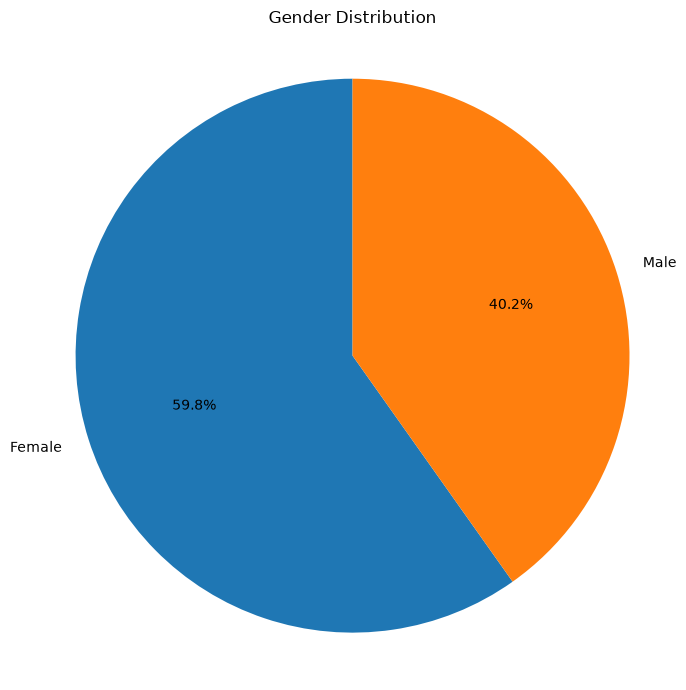

In [43]:
# visualizing gender distribution
gender_count = df['gender'].value_counts()

plt.figure(figsize=(7,7))
plt.pie(
    gender_count.values,
    labels = gender_count.index,
    autopct= '%1.1f%%',
    startangle = 90)
plt.title('Gender Distribution')
plt.axis('equal')
plt.tight_layout()
plt.show()

In [44]:
# which gender spends more per purchase
df.groupby('gender')['revenue'].mean().round(2)

gender
Female    688.14
Male      690.92
Name: revenue, dtype: float64

Female shoppers make up 59.81% (59,482) of all customers compared to 40.19% (39,975) for male shoppers. Since both genders spend nearly the same amount per order (₺688 vs ₺691), female customers drive total revenue purely through larger volume.

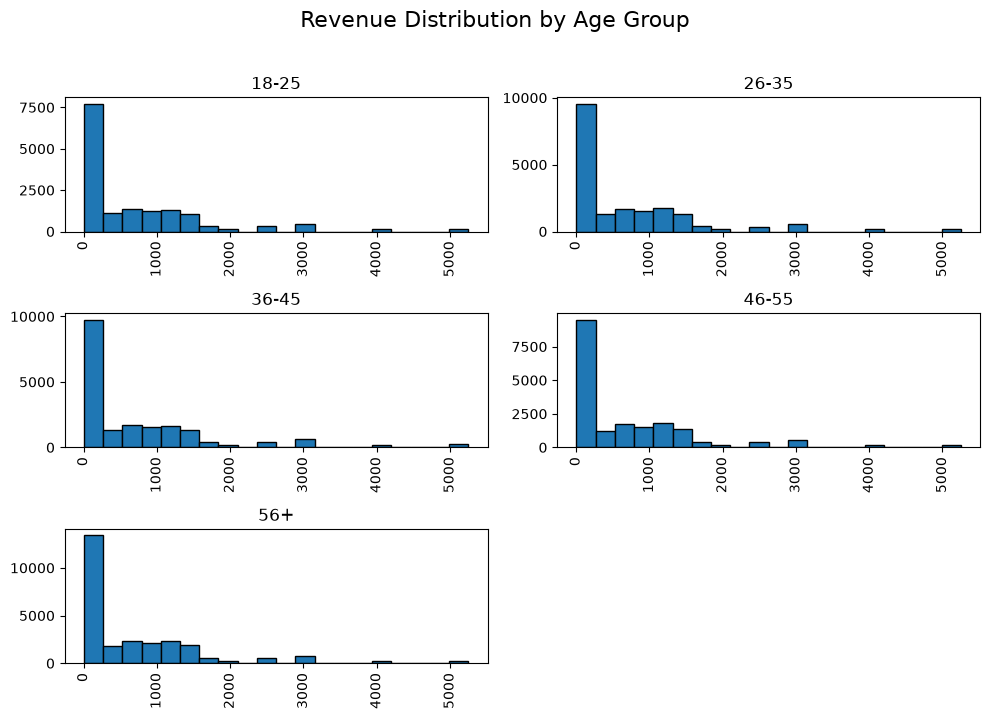

In [45]:
# visualizing revenue by age group
df['revenue'].hist(
    by = df['age_group'], 
    bins = 20, 
    figsize= (10, 7), 
    edgecolor = 'black')

plt.suptitle('Revenue Distribution by Age Group', fontsize = 16, y = 1.02)
plt.tight_layout()
plt.show()

Transaction revenue is heavily right-skewed across every age group, with most transactions clustering below ₺1000 and a long tail of high-value orders reaching up to ₺5,250. All 5 age groups share almost similar spending distributions and average order values (₺680-₺700).

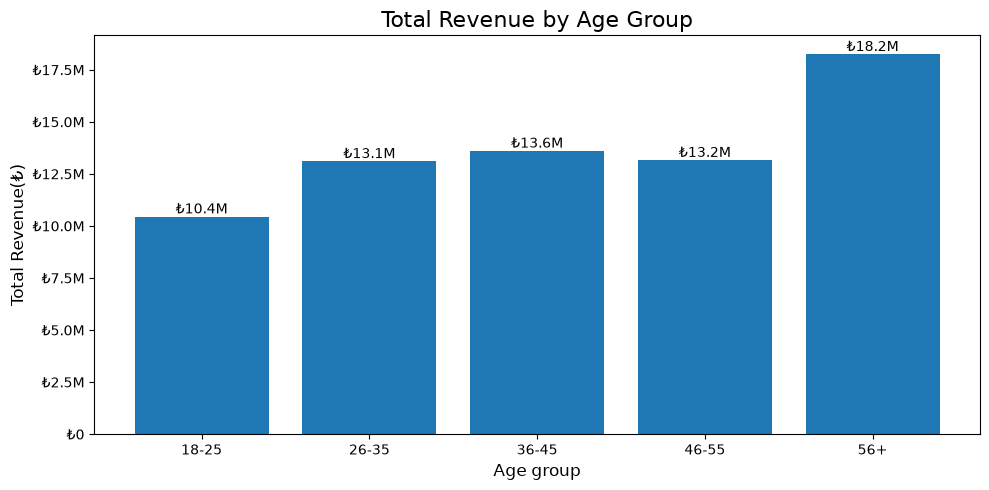

In [46]:
revenue_by_agegroup = df.groupby('age_group', observed = True)['revenue'].sum()
label = [format_lira(v, None) for v in revenue_by_agegroup.values]

plt.figure(figsize=(10,5))

bars = plt.bar(revenue_by_agegroup.index, revenue_by_agegroup.values)
plt.title('Total Revenue by Age Group', fontsize = 16)
plt.xlabel('Age group', fontsize = 12)
plt.ylabel('Total Revenue(₺)', fontsize = 12)
plt.gca().yaxis.set_major_formatter(FuncFormatter(format_lira))

plt.bar_label(bars, labels = label)
plt.tight_layout()
plt.show()

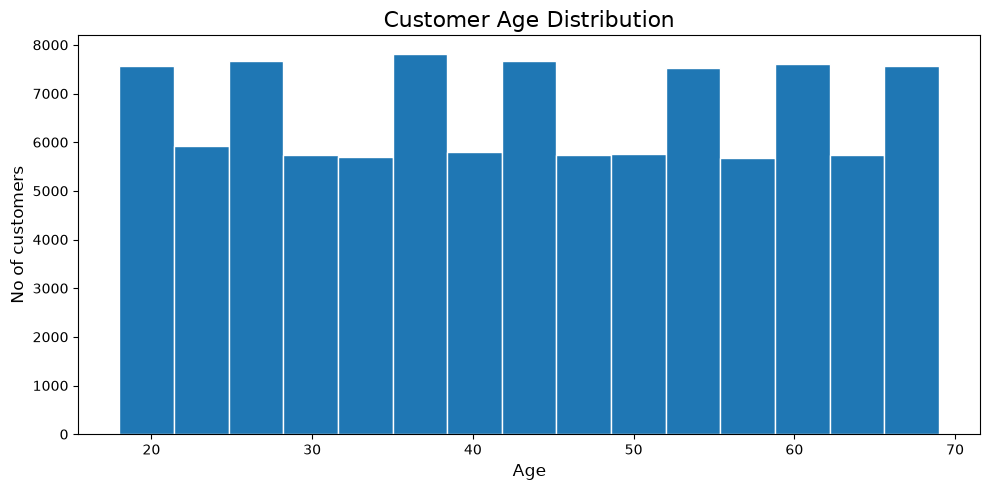

In [47]:
# age histogram
plt.figure(figsize = (10, 5))

plt.hist(df['age'], bins = 15, edgecolor = 'white')
plt.title('Customer Age Distribution', fontsize = 16)
plt.xlabel('Age', fontsize = 12)
plt.ylabel('No of customers', fontsize = 12)

plt.tight_layout()
plt.show()

Customer ages are evenly distributed between 18 and 69, with roughly 5,700-7,800 customers per bin. There is no concentration in a single age group, as customer base spans young adults, middle-aged shoppers and older customers evenly.

In [48]:
# category preferences by age group
age_category = pd.crosstab(df['age_group'], df['category'])
age_category

category,Books,Clothing,Cosmetics,Food & Beverage,Shoes,Souvenir,Technology,Toys
age_group,,,,,,,,
18-25,788,5337,2276,2306,1550,768,751,1583
26-35,920,6614,2895,2820,1928,970,962,1950
36-45,940,6711,2906,2942,1926,999,1040,1972
46-55,981,6609,2962,2773,1954,895,942,1900
56+,1352,9216,4058,3935,2676,1367,1301,2682


In [49]:
# percentage
age_category_pct = pd.crosstab(
    df['age_group'], 
    df['category'],
    normalize = 'index') * 100
age_category_pct.round(2)

category,Books,Clothing,Cosmetics,Food & Beverage,Shoes,Souvenir,Technology,Toys
age_group,,,,,,,,
18-25,5.13,34.75,14.82,15.01,10.09,5.00,4.89,10.31
26-35,4.83,34.70,15.19,14.80,10.12,5.09,5.05,10.23
36-45,4.84,34.53,14.95,15.14,9.91,5.14,5.35,10.15
46-55,5.16,34.75,15.58,14.58,10.28,4.71,4.95,9.99
56+,5.09,34.66,15.26,14.80,10.07,5.14,4.89,10.09


In [50]:
# preferences by gender
gender_category_pct = pd.crosstab(
    df['gender'], 
    df['category'],
    normalize = 'index') * 100
gender_category_pct.round(2)

category,Books,Clothing,Cosmetics,Food & Beverage,Shoes,Souvenir,Technology,Toys
gender,,,,,,,,
Female,4.89,34.72,15.25,14.80,10.03,5.07,5.01,10.23
Male,5.19,34.61,15.08,14.94,10.17,4.96,5.04,10.01


In [51]:
# payment_method preferences by age group
age_payment_pct = pd.crosstab(
    df['age_group'], 
    df['payment_method'],
    normalize = 'index') * 100
age_payment_pct.round(2)

payment_method,Cash,Credit Card,Debit Card
age_group,,,
18-25,44.52,35.30,20.18
26-35,44.72,34.91,20.37
36-45,44.65,35.15,20.19
46-55,44.50,35.25,20.25
56+,44.93,35.05,20.02


In [52]:
# payment_method preferences by gender
gender_payment_pct = pd.crosstab(
    df['gender'], 
    df['payment_method'],
    normalize = 'index') * 100
gender_payment_pct.round(2)

payment_method,Cash,Credit Card,Debit Card
gender,,,
Female,44.57,35.32,20.11
Male,44.87,34.82,20.31


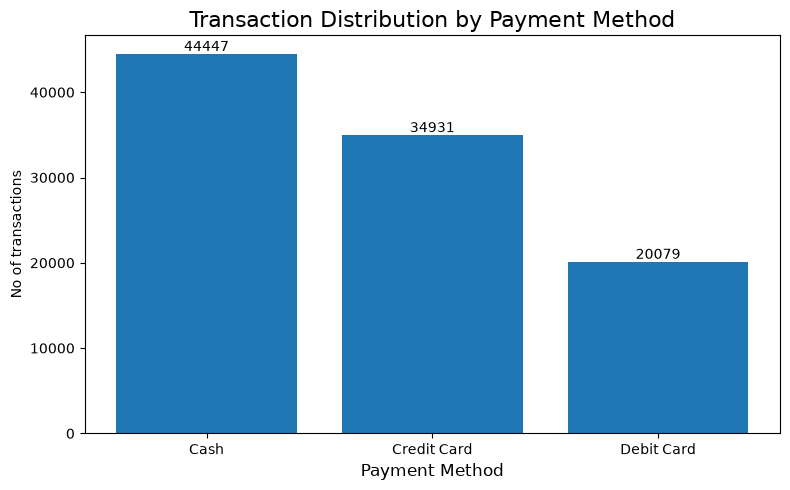

In [53]:
# payment method distribution
payment_count = df['payment_method'].value_counts()

plt.figure(figsize = (8, 5))
bars = plt.bar(payment_count.index, payment_count.values)

plt.title('Transaction Distribution by Payment Method', fontsize = 16)
plt.xlabel('Payment Method', fontsize = 12)
plt.ylabel('No of transactions')

plt.bar_label(bars)
plt.tight_layout()
plt.show()

Cash is the most common payment method (44.7%, 44, 447 transactions), followed by Credit Card (35.1%, 34, 931 transactions) and Debit Card (20.2%, 20,079 transactions). This payment split remains almost identical across all age groups and both genders.

In [54]:
# shopping mall preferences by age group
age_mall_pct = pd.crosstab(
    df['age_group'], 
    df['shopping_mall'],
    normalize = 'index') * 100
age_mall_pct.round(2)

shopping_mall,Cevahir AVM,Emaar Square Mall,Forum Istanbul,Istinye Park,Kanyon,Mall of Istanbul,Metrocity,Metropol AVM,Viaport Outlet,Zorlu Center
age_group,,,,,,,,,,
18-25,4.81,4.62,5.09,9.86,20.02,20.33,14.83,10.41,4.95,5.07
26-35,5.47,4.87,5.09,9.98,19.39,19.80,15.25,10.24,4.95,4.95
36-45,4.95,5.03,4.57,9.71,20.26,19.94,15.04,10.47,5.03,5.01
46-55,4.89,4.63,4.99,9.91,20.10,19.95,15.08,10.10,4.84,5.51
56+,4.95,4.95,5.10,9.75,19.91,20.22,15.18,9.99,4.93,5.01


In [71]:
# shopping mall preferences by gender
gender_mall_pct = pd.crosstab(
    df['gender'], 
    df['shopping_mall'],
    normalize = 'index') * 100
gender_mall_pct.round(2)

shopping_mall,Cevahir AVM,Emaar Square Mall,Forum Istanbul,Istinye Park,Kanyon,Mall of Istanbul,Metrocity,Metropol AVM,Viaport Outlet,Zorlu Center
gender,,,,,,,,,,
Female,4.94,4.78,5.07,9.88,20.02,20.01,15.03,10.33,4.96,4.99
Male,5.13,4.93,4.83,9.77,19.80,20.12,15.18,10.05,4.92,5.27


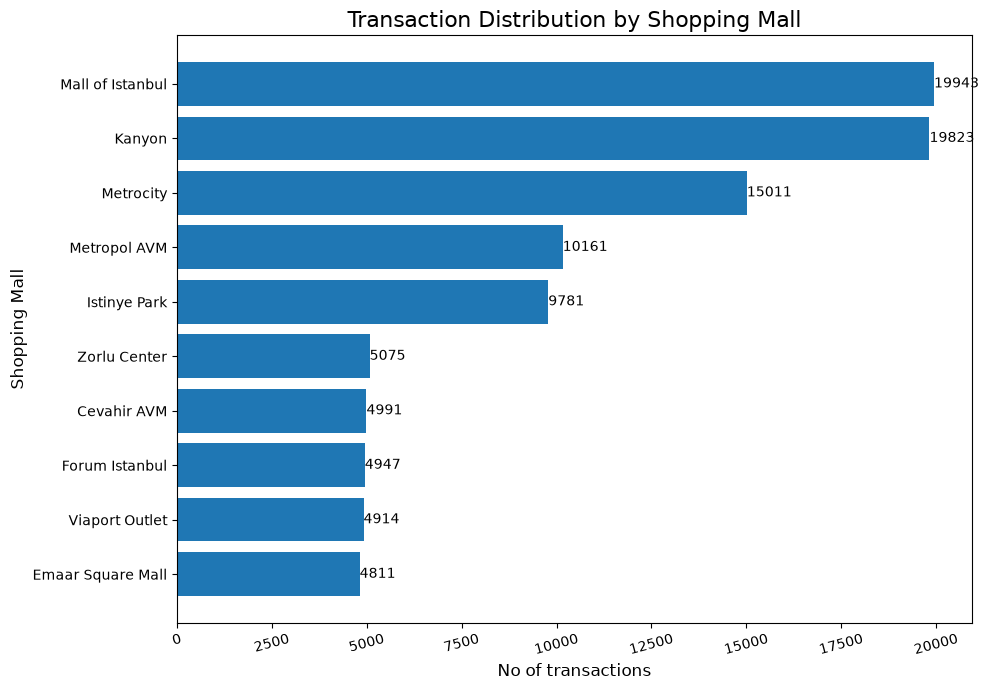

In [56]:
# shopping mall distribution
mall_count = df['shopping_mall'].value_counts()

plt.figure(figsize = (10, 7))
bars = plt.barh(mall_count.index, mall_count.values)

plt.title('Transaction Distribution by Shopping Mall', fontsize = 16)
plt.xlabel('No of transactions', fontsize = 12)
plt.ylabel('Shopping Mall', fontsize = 12)

plt.xticks(rotation = 15)
plt.gca().invert_yaxis()
plt.bar_label(bars)
plt.tight_layout()
plt.show()

Customer traffic is heavily concentrated in 3 malls: Mall of Istanbul(20.1%), Kanyon (19.9%) and Metrocity (15.1%), which together accounts for over half of all transactions, while smaller malls capture roughly 4.8%-10%. Location preferences are consistent across age and gender groups.

In [57]:
# revenue by gender and age group
gender_age = df.groupby(['age_group', 'gender'], observed = True) ['revenue'].agg(['count', 'sum', 'mean'])
gender_age

count          sum        mean
age_group gender                                
18-25     Female   9082   6300820.36  693.770134
          Male     6277   4143952.07  660.180352
26-35     Female  11410   7769309.73  680.921098
          Male     7649   5332046.67  697.090688
36-45     Female  11762   8152636.02  693.133482
          Male     7674   5451080.87  710.331101
46-55     Female  11334   7804055.68  688.552645
          Male     7682   5353042.28  696.829248
56+       Female  15894  10904979.83  686.106696
          Male    10693   7339442.40  686.378229

Customer demographics, category share, payment methods and shopping mall traffic stay very consistent across age groups and genders. The differences in total revenue mostly come down to high transaction volume, seen for female customers (59.81% unique customers) and larger age groups like 56+.

CATEGORY ANALYSIS

The dataset doesn't have products, only categories, so the analysis will be carried out for the product categories instead.

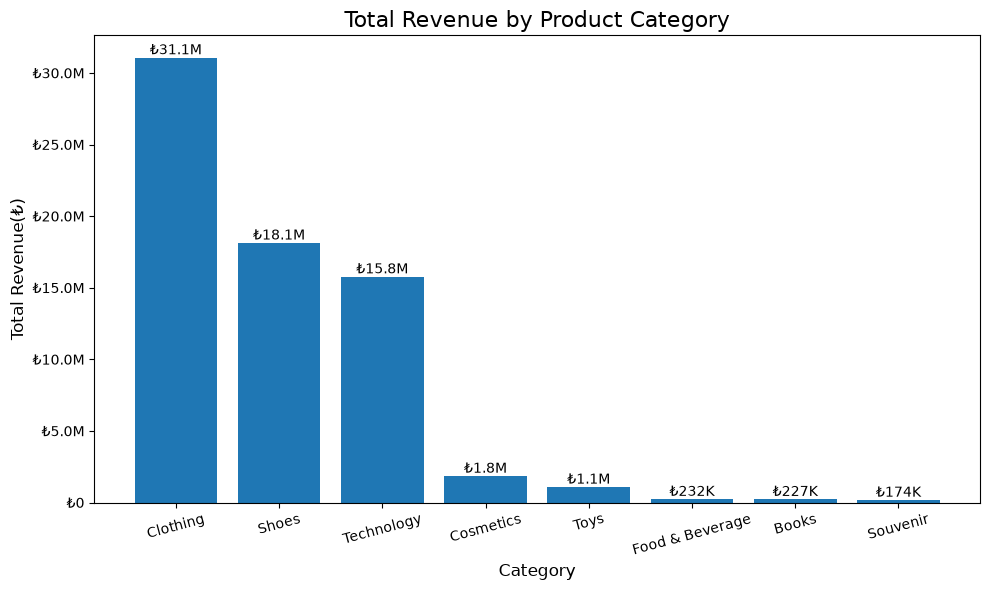

In [58]:
# revenue by category
category_sale = df.groupby('category')['revenue'].sum().sort_values(ascending =False)
label = [format_lira(v, None) for v in category_sale.values]

plt.figure(figsize=(10,6))

bars = plt.bar(category_sale.index, category_sale.values)

plt.title('Total Revenue by Product Category', fontsize = 16)
plt.xlabel('Category', fontsize = 12)
plt.ylabel('Total Revenue(₺)', fontsize = 12)
plt.gca().yaxis.set_major_formatter(FuncFormatter(format_lira))


plt.bar_label(bars, labels = label)
plt.xticks(rotation = 15)
plt.tight_layout()
plt.show()

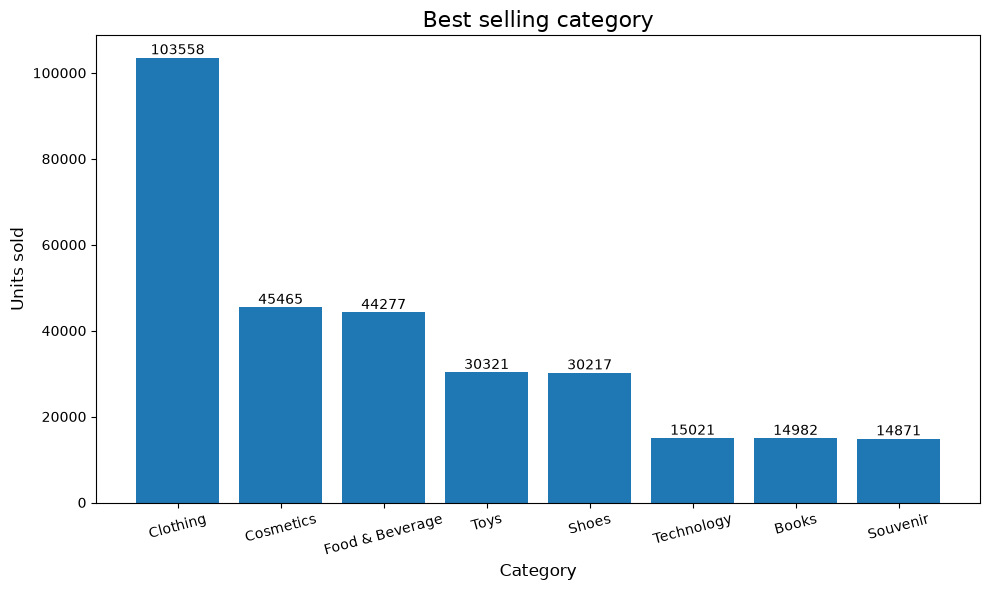

In [70]:
# Best selling category 
best_selling_cat = (df.groupby('category')['quantity'].sum().sort_values(ascending =False))

plt.figure(figsize=(10,6))

bars = plt.bar(best_selling_cat.index, best_selling_cat.values)

plt.title('Best selling category', fontsize = 16)
plt.xlabel('Category', fontsize = 12)
plt.ylabel('Units sold', fontsize = 12)

plt.bar_label(bars)
plt.xticks(rotation = 15)
plt.tight_layout()
plt.show()

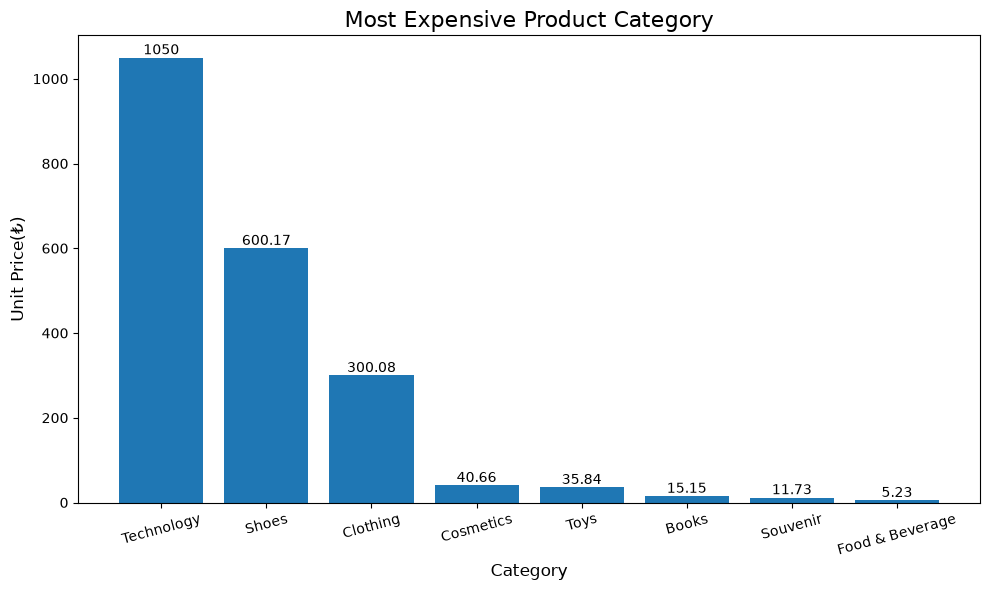

In [60]:
# Most expensive category
expensive_category = df.groupby('category')['unit_price'].first().sort_values(ascending = False)

plt.figure(figsize=(10,6))

bars = plt.bar(expensive_category.index, expensive_category.values)

plt.title('Most Expensive Product Category', fontsize = 16)
plt.xlabel('Category', fontsize = 12)
plt.ylabel('Unit Price(₺)', fontsize = 12)

plt.bar_label(bars)
plt.xticks(rotation = 15)
plt.tight_layout()
plt.show()

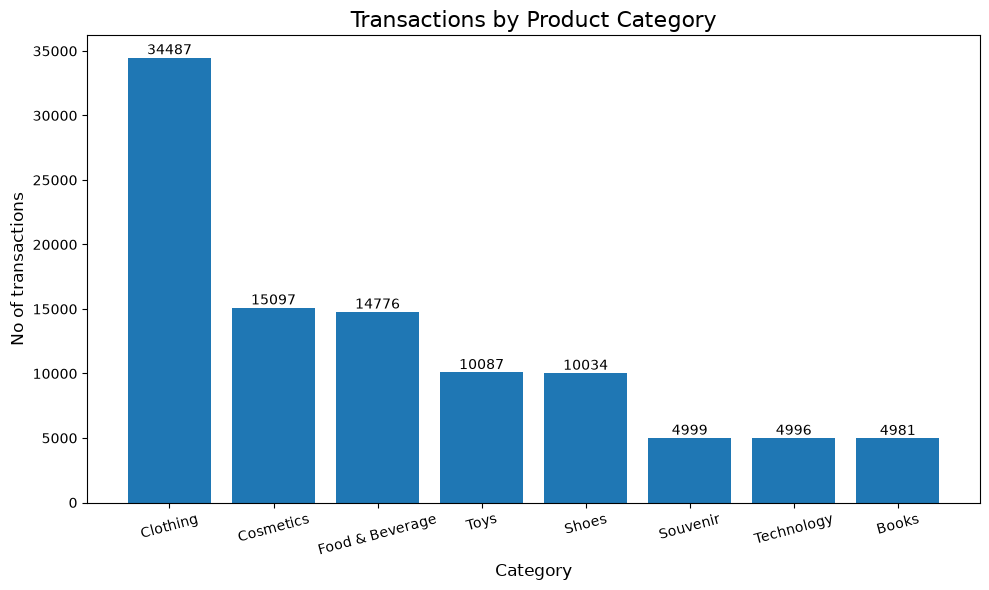

In [61]:
# transactions by category
category_txns = df['category'].value_counts().sort_values(ascending = False)

plt.figure(figsize=(10,6))

bars = plt.bar(category_txns.index, category_txns.values)

plt.title('Transactions by Product Category', fontsize = 16)
plt.xlabel('Category', fontsize = 12)
plt.ylabel('No of transactions', fontsize = 12)

plt.bar_label(bars)
plt.xticks(rotation = 15)
plt.tight_layout()
plt.show()

In [62]:
# category revenue share, volume share and average quantity per transaction
cat_summary = df.groupby('category').agg(
        transactions = ('category', 'count'),
        total_revenue = ('revenue', 'sum'),
        units_sold = ('quantity', 'sum'),
        avg_qty_per_txn = ('quantity', 'mean'),
        unit_price = ('unit_price', 'first')
    )
cat_summary['revenue_share_pct'] = (
    cat_summary['total_revenue']/cat_summary['total_revenue'].sum() * 100).round(2)

cat_summary['volume_share_pct'] = (
    cat_summary['units_sold']/cat_summary['units_sold'].sum() * 100).round(2)

cat_summary['avg_qty_per_txn'] = cat_summary['avg_qty_per_txn'].round(2)

cat_summary = cat_summary.sort_values('total_revenue', ascending=False)
cat_summary

,transactions,total_revenue,units_sold,avg_qty_per_txn,unit_price,revenue_share_pct,volume_share_pct
category,,,,,,,
Clothing,34487,31075684.64,103558,3.00,300.08,45.33,34.67
Shoes,10034,18135336.89,30217,3.01,600.17,26.46,10.12
Technology,4996,15772050.00,15021,3.01,1050.00,23.01,5.03
Cosmetics,15097,1848606.90,45465,3.01,40.66,2.70,15.22
Toys,10087,1086704.64,30321,3.01,35.84,1.59,10.15
Food & Beverage,14776,231568.71,44277,3.00,5.23,0.34,14.82
Books,4981,226977.30,14982,3.01,15.15,0.33,5.02
Souvenir,4999,174436.83,14871,2.97,11.73,0.25,4.98


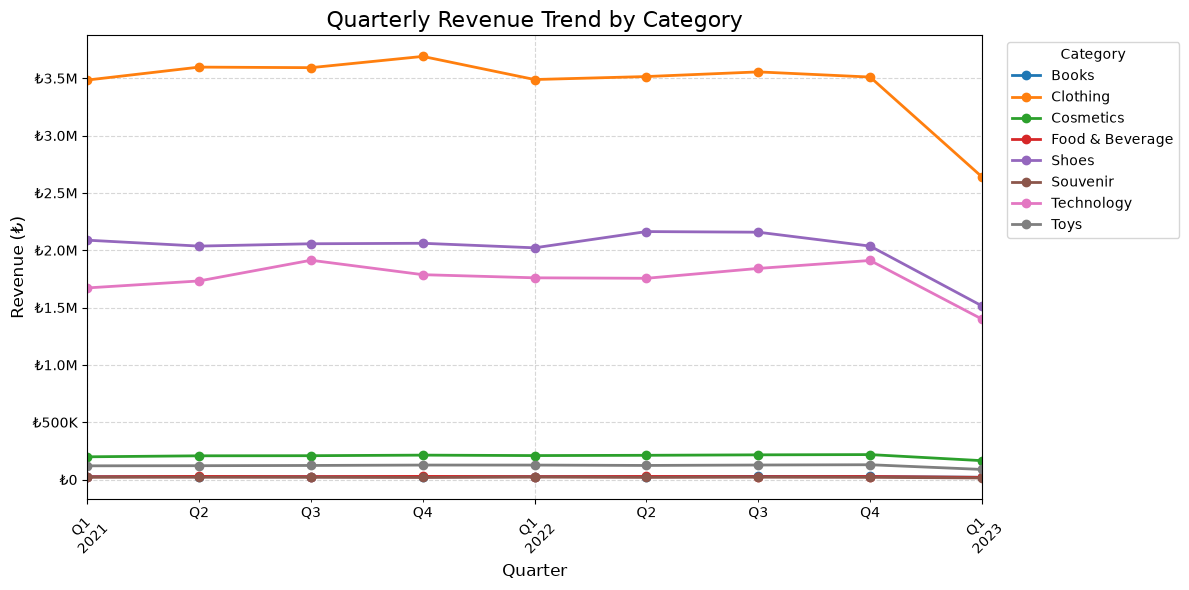

In [63]:
# Category revenue trend
cat_qtr_rev = df.pivot_table(
    index = df['invoice_date'].dt.to_period('Q'),
    columns = 'category',
    values = 'revenue', 
    aggfunc = 'sum')

ax = cat_qtr_rev.plot(figsize= (12, 6), marker = 'o', linewidth = 2, linestyle = '-')

ax.yaxis.set_major_formatter(FuncFormatter(format_lira))
plt.title('Quarterly Revenue Trend by Category', fontsize = 16)
plt.xlabel('Quarter', fontsize = 12)
plt.ylabel('Revenue (₺)', fontsize = 12)
plt.legend(title = 'Category', bbox_to_anchor = (1.02, 1), loc = 'upper left')

plt.xticks(rotation = 45)
plt.grid(True, linestyle = '--', alpha = 0.5)
plt.tight_layout()
plt.show()

Clothing leads in revenue(₺31.1M), units sold (103,558) and transactions (34,487), followed by Shoes(₺18.1M) and Technology (₺15.8M) in total sales. Although Technology is the most expensive category (unit price of ₺1,050), it ranks 3rd in total revenue because its transaction volume is low (4,996 transactions). Shoes (₺600.17) and Clothing (₺300.08) combines moderate-to-high unit prices with high volume to drive the top revenue. 
From Q1 2021 to Q4 2022, quarterly revenue stays steady in 3 clear tiers without seasonal spikes: Clothing leads (₺3.4M-₺3.6M), followed by Shoes(₺2.0M-₺2.2M) and Technology (₺1.7M-₺1.9M), while the remaining categories stay flat below ₺250k. The drop in Q1 2023 happens only because the dataset ends on March 8, 2023. 

CORRELATION ANALYSIS

In [64]:
# correlation matrix
correl_matrix = df[numeric_cols].corr()
correl_matrix

,age,quantity,revenue,unit_price
age,1.000000,0.000667,0.001694,-0.000670
quantity,0.000667,1.000000,0.344880,0.001676
revenue,0.001694,0.344880,1.000000,0.850212
unit_price,-0.000670,0.001676,0.850212,1.000000


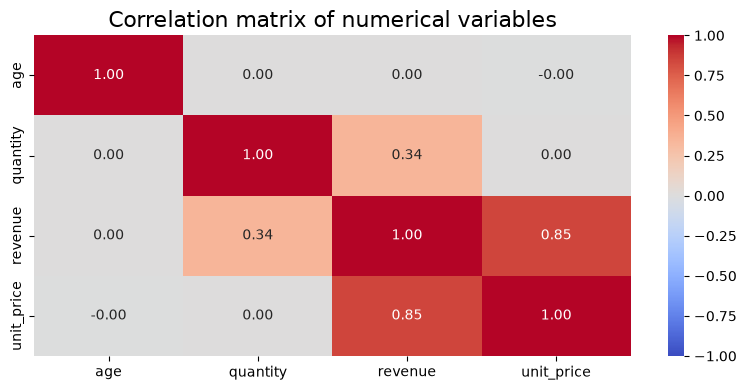

In [69]:
# visualizing the matrix using a heatmap
plt.figure(figsize = (8, 4))

sns.heatmap(
    correl_matrix,
    annot = True, 
    cmap = 'coolwarm', 
    fmt = '.2f',
    vmin = -1,
    vmax = 1)
plt.title('Correlation matrix of numerical variables', fontsize = 16)
plt.tight_layout()
plt.show()

Revenue is driven mainly by unit_price (r= 0.85) and moderately by quantity (r= 0.34). It is equal to the product of quantity and unit price, so its correlation with both variables is partly built in. Customer age has no relationship with quantity, unit price or revenue (r= 0.00) as customers buy similar quantities and chose similarly priced items regardless of age. Quantity is also independent of item price (r= 0.00) as customers do not buy fewer units when items are cheap.

Recommendations:

1. Clothing (₺31.1M) , Shoes (₺18.1M) and Technology (₺15.8M) are leading in revenue, with Clothing also leading order volume. Keep them well stocked and prioritise them in promotions.
2. Technology has the highest unit price (₺1,050) but only 4,996 transactions, so bundles, installment offers or targeted campaigns could lift its sales.
3. Put more promotional energy into top--traffic malls like Mall of Istanbul, Kanyon and Metrocity, while keeping a closer eye on costs and local demand in the smaller malls.
4. Across each year, sales climb from Q1 to Q3 (peak quarter) and then stay flat in Q4 instead of rising, despite the year-end shopping season, so run holiday and year-end promotions to capture that missed demand.
5. Since shoppers across age groups and genders behave pretty much the same, try simple bundle deals or small spend-based discounts at checkout to nudge order sizes up.

SAVING AND EXPORTING TO CSV

In [72]:
df.to_csv('cleaned_customer_shopping_data.csv', index = False)